In [32]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df = pd.read_csv('/content/bank[1].csv')

In [34]:
#understanding the dataset
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [35]:
df.shape

(11162, 17)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [37]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [38]:
print(df['deposit'].value_counts())

deposit
no     5873
yes    5289
Name: count, dtype: int64


In [39]:
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].unique())


job:
['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']

marital:
['married' 'single' 'divorced']

education:
['secondary' 'tertiary' 'primary' 'unknown']

default:
['no' 'yes']

housing:
['yes' 'no']

loan:
['no' 'yes']

contact:
['unknown' 'cellular' 'telephone']

month:
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

poutcome:
['unknown' 'other' 'failure' 'success']

deposit:
['yes' 'no']


In [42]:
num_cols = df.select_dtypes(include=np.number).columns
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


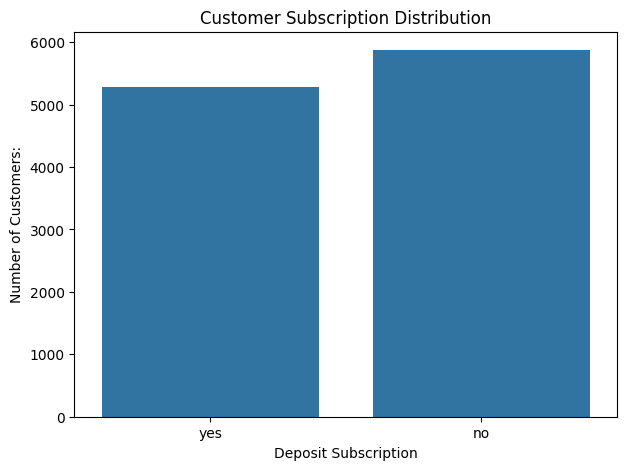

In [43]:
#Univariate analysis
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='deposit')
plt.title("Customer Subscription Distribution")
plt.xlabel("Deposit Subscription")
plt.ylabel("Number of Customers:")
plt.show()

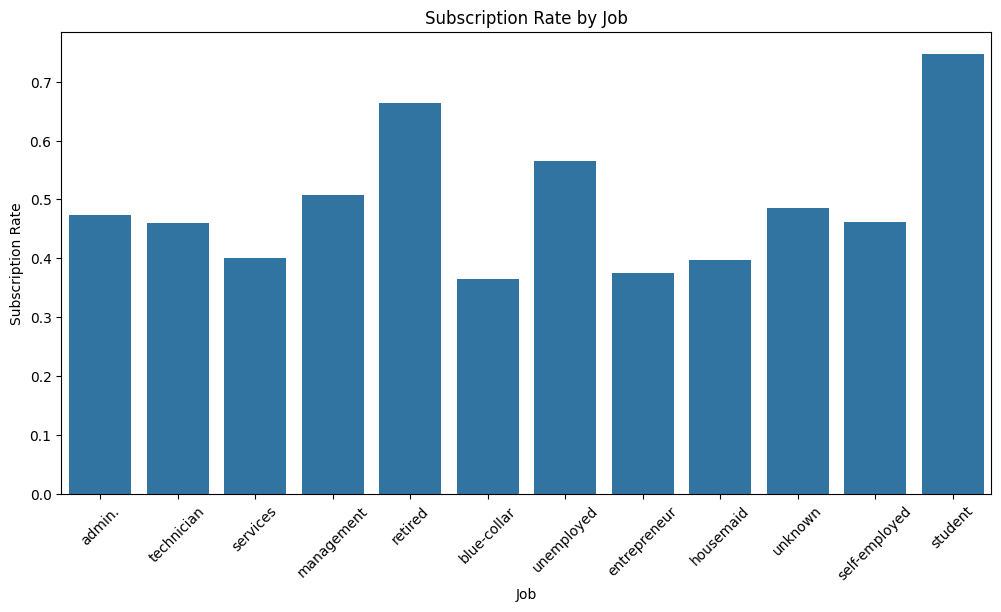

In [44]:
#bivariate analysis
plt.figure(figsize=(12,6))
sns.barplot(data=df,x='job',y=df['deposit'].map({'yes':1, 'no':0}),errorbar=None)
plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate")
plt.xticks(rotation=45)
plt.show()

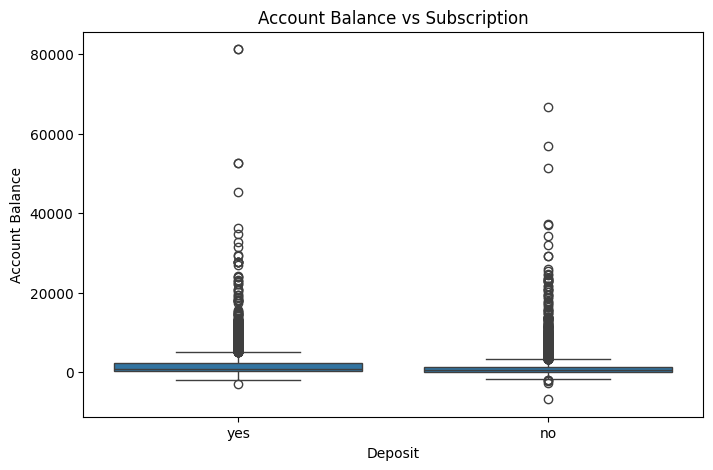

In [45]:
#outliers
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='deposit', y='balance')
plt.title("Account Balance vs Subscription")
plt.xlabel("Deposit")
plt.ylabel("Account Balance")
plt.show()

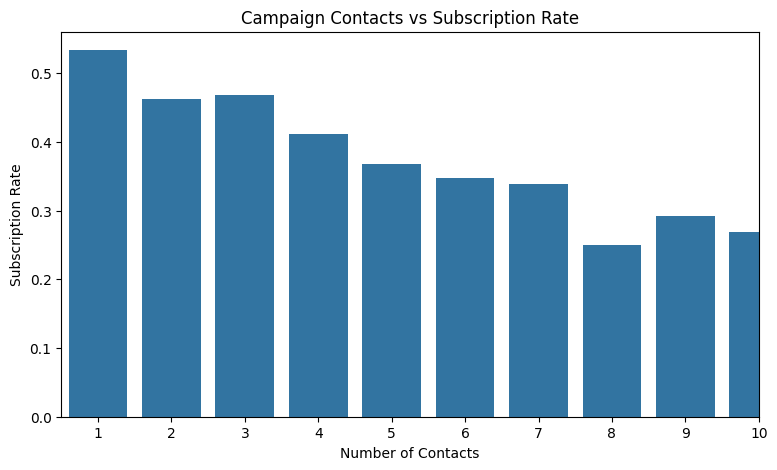

In [46]:

plt.figure(figsize=(9,5))

sns.barplot(data=df,x='campaign',y=df['deposit'].map({'yes':1, 'no':0}),errorbar=None)
plt.title("Campaign Contacts vs Subscription Rate")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate")
plt.xlim(-0.5, 9)
plt.show()

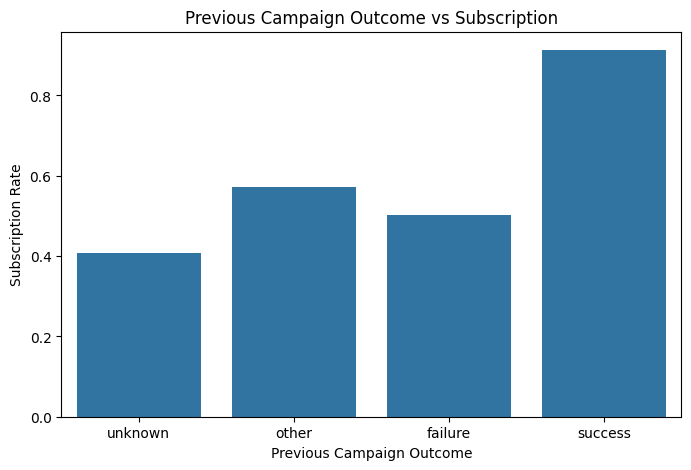

In [47]:

plt.figure(figsize=(8,5))

sns.barplot(data=df,x='poutcome',y=df['deposit'].map({'yes':1, 'no':0}),errorbar=None)
plt.title("Previous Campaign Outcome vs Subscription")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate")
plt.show()

In [48]:
# Separate features and target
X = df.drop(columns=['deposit', 'duration'])

y = df['deposit'].map({'no': 0, 'yes': 1})

print(X.shape)
print(y.shape)

(11162, 15)
(11162,)


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8929, 15)
(2233, 15)
(8929,)
(2233,)


In [50]:
#identifying numerical and categorical features
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include='object').columns

print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [51]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)

X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [52]:
#scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [53]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [56]:
#predicting lr_model
y_pred = lr_model.predict(X_test)
print(y_pred)

[0 0 1 ... 1 0 1]


In [57]:
#accuracy predictions
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.6954769368562472


In [59]:
#classification report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.67      0.82      0.74      1175
           1       0.73      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233



In [60]:
#confusion_matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[958 217]
 [463 595]]


In [61]:
#Random_Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [62]:
y_pred_rf = rf_model.predict(X_test)

In [63]:
from sklearn.metrics import accuracy_score
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.7232422749664129


In [64]:
#classification_report_for_randomforest
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.71      0.81      0.75      1175
           1       0.75      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.72      0.72      2233



In [65]:
#Gradient_Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [66]:
y_pred_gb = gb_model.predict(X_test)

In [67]:
#accuracy_gradient_boosting
from sklearn.metrics import accuracy_score
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print("Gradient Boosting Accuracy:", accuracy_gb)

Gradient Boosting Accuracy: 0.7407075682937752


In [68]:
#classification_gradient_boosting
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.71      0.86      0.78      1175
           1       0.80      0.60      0.69      1058

    accuracy                           0.74      2233
   macro avg       0.75      0.73      0.73      2233
weighted avg       0.75      0.74      0.74      2233



In [69]:
#feature_importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

             Feature  Importance
48  poutcome_success    0.254949
33   contact_unknown    0.136532
0                age    0.074313
1            balance    0.061682
2                day    0.059482
4              pdays    0.047701
28       housing_yes    0.043597
41         month_mar    0.039514
34         month_apr    0.031813
3           campaign    0.029634
40         month_jun    0.027484
27        housing_no    0.027046
44         month_oct    0.026331
37         month_feb    0.014183
30          loan_yes    0.013444


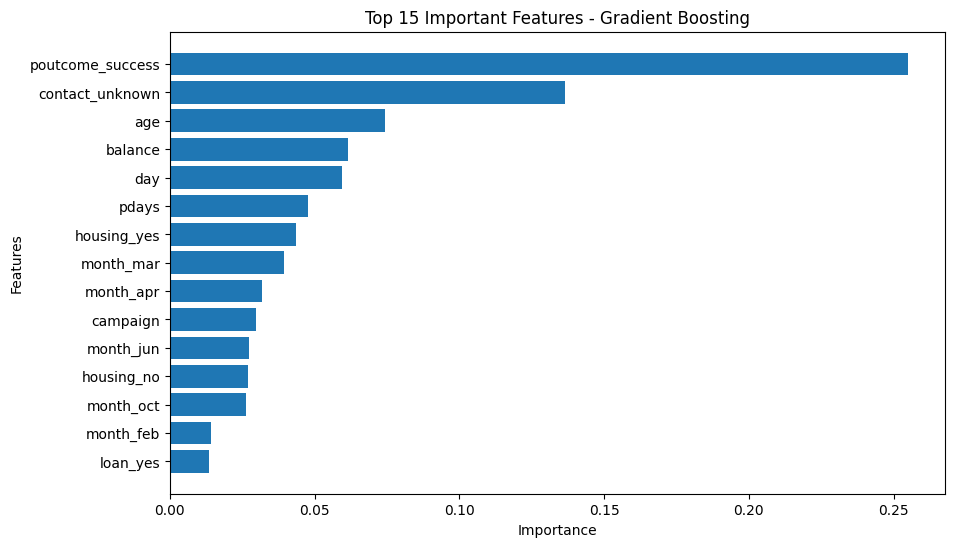

In [70]:
#visualising_feature_importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'].head(15),
    feature_importance['Importance'].head(15)
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Gradient Boosting")
plt.gca().invert_yaxis()

plt.show()

In [71]:
gb_tuned = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_tuned.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)

In [72]:
y_pred_tuned = gb_tuned.predict(X_test)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print("Tuned Gradient Boosting Accuracy:", accuracy_tuned)

Tuned Gradient Boosting Accuracy: 0.7380206000895656


In [73]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.71      0.86      0.78      1175
           1       0.80      0.60      0.69      1058

    accuracy                           0.74      2233
   macro avg       0.75      0.73      0.73      2233
weighted avg       0.75      0.74      0.73      2233



In [74]:
from sklearn.metrics import roc_auc_score

lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, lr_prob))
print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("Gradient Boosting ROC-AUC:", roc_auc_score(y_test, gb_prob))

Logistic Regression ROC-AUC: 0.7578546434460846
Random Forest ROC-AUC: 0.7766033865583397
Gradient Boosting ROC-AUC: 0.7935116438080683


In [75]:
#comparison table
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy,
        accuracy_rf,
        accuracy_gb
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob)
    ]
})

print(results)

                 Model  Accuracy   ROC-AUC
0  Logistic Regression  0.695477  0.757855
1        Random Forest  0.723242  0.776603
2    Gradient Boosting  0.740708  0.793512
